![JohnSnowLabs](https://nlp.johnsnowlabs.com/assets/images/logo.png)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JohnSnowLabs/spark-nlp-workshop/blob/master/tutorials/Certification_Trainings/Training_Notebooks%20%26%20Slides/Fall_2026/4.Day-4_Medical_Language_Models_for_Data_Scientists/vnlp/basics/SparkOCRDocumentLayoutAnalyzerTextExtraction.ipynb)

# Document Layout Analyze
Let's explore Layout Analysis & OCR


In [1]:
secret = ""
license = ""
version = secret.split("-")[0]
spark_ocr_jar_path = "../"

In [2]:
# install from PYPI using secret
#%pip install spark-ocr==$version --extra-index-url=https://pypi.johnsnowlabs.com/$secret --upgrade

## Initialize Spark Session

In [3]:
from pyspark.sql import SparkSession
from sparkocr import start
import os

if license:
    os.environ['SPARK_OCR_LICENSE'] = license

spark = start(secret=secret, jar_path=spark_ocr_jar_path)
spark

Spark version: 3.4.1
Spark NLP version: 7.0.0
Spark NLP for Healthcare version: 6.4.1
Spark OCR version: 7.0.0

:: loading settings :: url = jar:file:/opt/pytorch/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/ubuntu/.ivy2/cache
The jars for the packages stored in: /home/ubuntu/.ivy2/jars
com.johnsnowlabs.nlp#spark-nlp_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-9f5997f8-765c-403b-99b2-8268c888f544;1.0
	confs: [default]
	found com.johnsnowlabs.nlp#spark-nlp_2.12;7.0.0 in central
	found com.typesafe#config;1.4.2 in central
	found org.rocksdb#rocksdbjni;6.29.5 in central
	found com.amazonaws#aws-java-sdk-s3;1.12.500 in central
	found com.amazonaws#aws-java-sdk-kms;1.12.500 in central
	found com.amazonaws#aws-java-sdk-core;1.12.500 in central
	found commons-logging#commons-logging;1.1.3 in central
	found commons-codec#commons-codec;1.15 in central
	found org.apache.httpcomponents#httpclient;4.5.13 in central
	found org.apache.httpcomponents#httpcore;4.4.13 in central
	found software.amazon.ion#ion-java;1.0.2 in central
	found joda-time#joda-time;2.8.1 in central
	found com.amazonaws#jmespath-java;1.12.500 in centra

	found org.apache.pdfbox#xmpbox;2.0.16 in central
	found de.rototor.pdfbox#graphics2d;0.24 in central
	found com.openhtmltopdf#openhtmltopdf-rtl-support;1.0.0 in central
	found com.ibm.icu#icu4j;59.1 in central
	found com.openhtmltopdf#openhtmltopdf-jsoup-dom-converter;1.0.0 in central
	found com.vladsch.flexmark#flexmark-profile-pegdown;0.61.34 in central
	found com.vladsch.flexmark#flexmark-youtrack-converter;0.61.34 in central
	found org.ccil.cowan.tagsoup#tagsoup;1.2.1 in central
	found org.json4s#json4s-native_2.12;3.7.0-M11 in central
	found org.json4s#json4s-core_2.12;3.7.0-M11 in central
	found org.json4s#json4s-ast_2.12;3.7.0-M11 in central
	found org.json4s#json4s-scalap_2.12;3.7.0-M11 in central
	found com.thoughtworks.paranamer#paranamer;2.8 in central
	found com.johnsnowlabs.nlp#tensorflow-cpu_2.12;0.4.4 in central
	found com.microsoft.onnxruntime#onnxruntime;1.23.0 in central
	found com.johnsnowlabs.nlp#jsl-llamacpp-cpu;2.0.4 in central
	found org.jetbrains#annotations;24

:: retrieving :: org.apache.spark#spark-submit-parent-9f5997f8-765c-403b-99b2-8268c888f544
	confs: [default]
	0 artifacts copied, 189 already retrieved (0kB/26ms)
26/10/09 19:42:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


In [4]:
import pkg_resources

from pyspark.ml import PipelineModel
import pyspark.sql.functions as f

from sparkocr import start
from sparkocr.transformers import *
from sparkocr.enums import *
from sparkocr.utils import *
from sparkocr.metrics import score

/tmp/ipykernel_25907/228604372.py:1: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  import pkg_resources


## Load Sample PDF

In [ ]:
from pyspark.ml import PipelineModel
import pyspark.sql.functions as f
from sparkocr.transformers import *
from sparkocr.enums import *
from sparkocr.utils import display_images

pdf_path = "../mixed_formats/*.pdf"
pdf_df = spark.read.format("binaryFile").load(pdf_path)
pdf_to_image = PdfToImage() \
    .setImageType(ImageType.TYPE_3BYTE_BGR)

display_images(pdf_to_image.transform(pdf_df), "image")

## Load Pipeline


In [16]:
layout_detector = ImageObjectDetectorRtDetr \
    .pretrained("jsl_layout_heron_opt", "en", "clinical/ocr") \
    .setInputCol("image") \
    .setOutputCol("regions") \
    .setScoreThreshold(.5)

splitter = ImageSplitRegions() \
    .setInputCol("image") \
    .setInputRegionsCol("regions") \
    .setOutputCol("layout_element") \
    .setDropCols("image") \
    .setImageType(ImageType.TYPE_3BYTE_BGR)

# Extract text from image
ocr = ImageToText() \
    .setInputCol("layout_element") \
    .setOutputCol("text") \
    .setIgnoreResolution(False) \
    .setPageIteratorLevel(PageIteratorLevel.SYMBOL) \
    .setPageSegMode(PageSegmentationMode.SPARSE_TEXT) \
    .setConfidenceThreshold(70)

draw_regions = ImageDrawRegions() \
    .setInputCol("image") \
    .setInputRegionsCol("regions") \
    .setOutputCol("image_with_regions") \
    .setRectColor(Color.green)

pipeline = PipelineModel(stages=[
    pdf_to_image,
    layout_detector,
    splitter,
    ocr
])

publaynet_dit_base_mrcnn_jsl download started this may take some time.


26/10/09 19:48:04 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/10/09 19:48:04 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.


Approximate size to download 401.2 MB
jsl_layout_heron_opt download started this may take some time.
Approximate size to download 152.8 MB


26/10/09 19:48:04 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.
26/10/09 19:48:04 WARN S3AbortableInputStream: Not all bytes were read from the S3ObjectInputStream, aborting HTTP connection. This is likely an error and may result in sub-optimal behavior. Request only the bytes you need via a ranged GET or drain the input stream after use.


jsl_layout_heron_opt download started this may take some time.
Approximate size to download 152.8 MB
Download done! Loading the resource.


## Call the pipeline

In [23]:
pipeline.transform(pdf_df).printSchema()

root
 |-- path: string (nullable = true)
 |-- modificationTime: timestamp (nullable = true)
 |-- length: long (nullable = true)
 |-- image: struct (nullable = true)
 |    |-- origin: string (nullable = true)
 |    |-- height: integer (nullable = false)
 |    |-- width: integer (nullable = false)
 |    |-- nChannels: integer (nullable = false)
 |    |-- mode: integer (nullable = false)
 |    |-- resolution: integer (nullable = false)
 |    |-- data: binary (nullable = true)
 |-- total_pages: integer (nullable = true)
 |-- pagenum: integer (nullable = true)
 |-- documentnum: string (nullable = false)
 |-- image_dims: struct (nullable = false)
 |    |-- width: string (nullable = true)
 |    |-- height: string (nullable = true)
 |-- regions: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- index: integer (nullable = false)
 |    |    |-- page: integer (nullable = false)
 |    |    |-- x: float (nullable = false)
 |    |    |-- y: float (nullable = fals

In [17]:
it = pipeline.transform(pdf_df).select("text").cache().toLocalIterator()

In [25]:
print(next(it).text)


Paqe 16 of 42


In [28]:
print(next(it).text)


Assessment/Plan


In [20]:
print(next(it).text)


Acute on chronic diastolic heart failure exacerbation. Small pleural effusions bilateratly
with mild pulmonary vascular congestion on chest x-ray, slighi elevation in BNP. We'll
continue 1 more day af lV diuresis with 80 mg IV Lasix. He may have had a viral infection
which precipitated this. We'll add Tylenol ‘oz his joint pains. Continue atenolol and
chiorthalidone.


## Show the regions


    Image #0:
    Origin: file:/home/ubuntu/trainings_october_2026/mixed_formats/h_and_p.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: 5
    Number of channels: 3


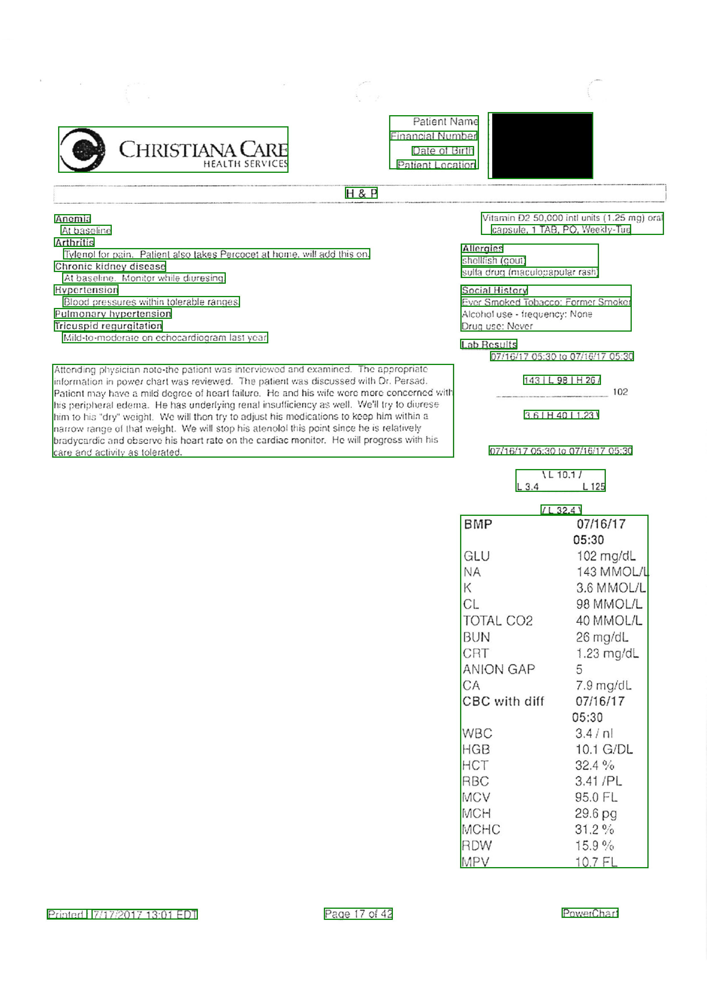


    Image #1:
    Origin: file:/home/ubuntu/trainings_october_2026/mixed_formats/PDF_Deid_Deidentification_0.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: 5
    Number of channels: 3


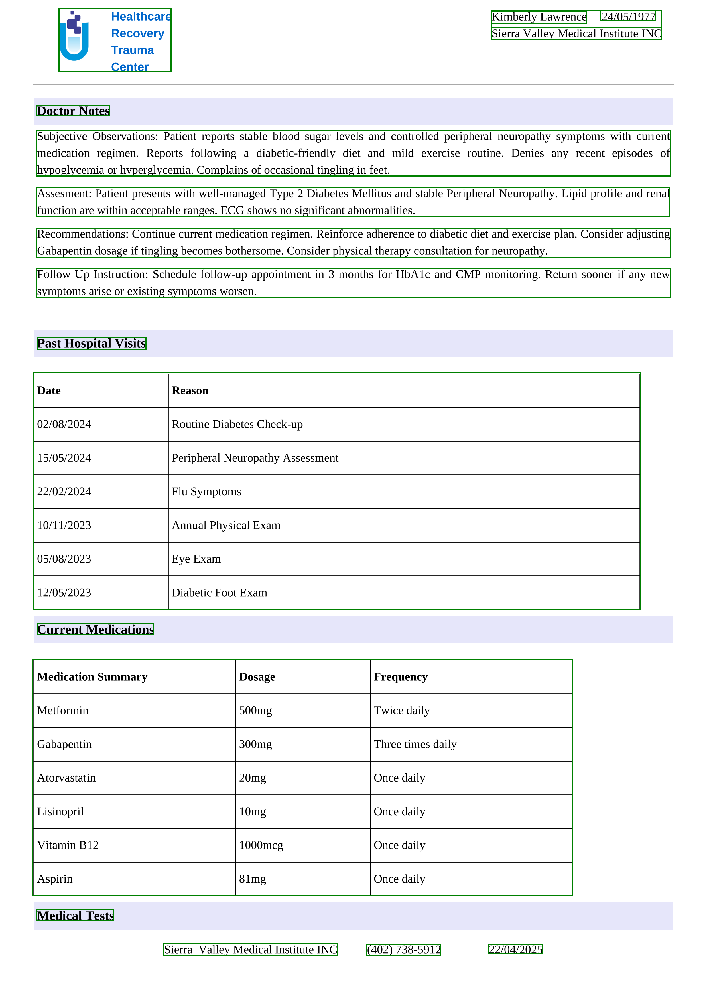


    Image #2:
    Origin: file:/home/ubuntu/trainings_october_2026/mixed_formats/report.pdf
    Resolution: 300 dpi
    Width: 4241 px
    Height: 2650 px
    Mode: 5
    Number of channels: 3


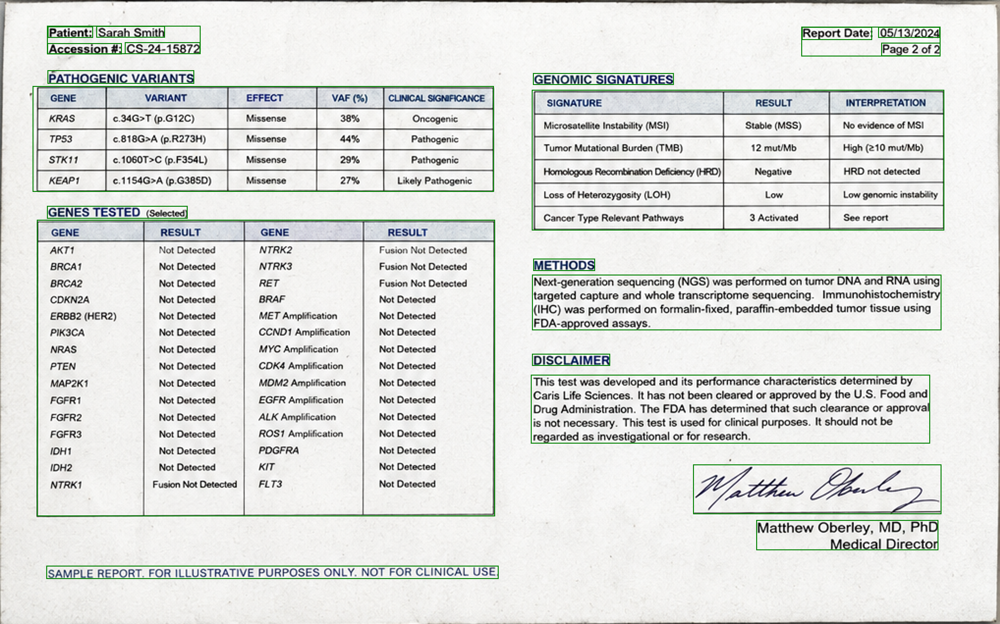


    Image #3:
    Origin: file:/home/ubuntu/trainings_october_2026/mixed_formats/handwritten.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: 5
    Number of channels: 3


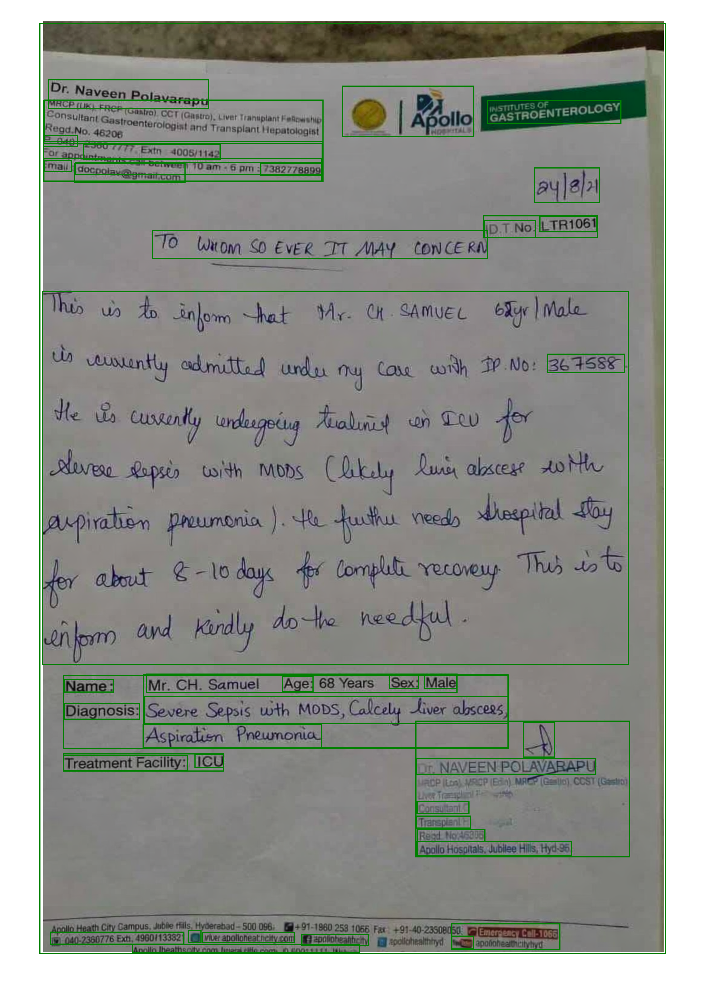


    Image #4:
    Origin: file:/home/ubuntu/trainings_october_2026/mixed_formats/h_and_p.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: 5
    Number of channels: 3


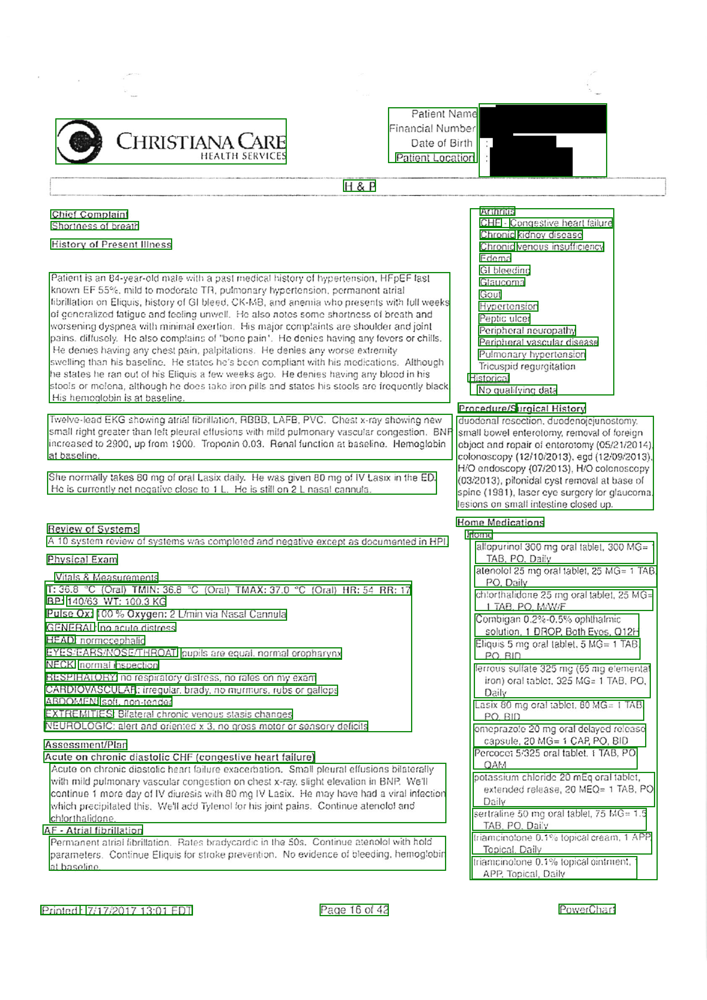

In [21]:
pipeline = PipelineModel(stages=[pdf_to_image, layout_detector, draw_regions])
result = pipeline.transform(pdf_df).cache()
display_images(result, "image_with_regions")